# WattIf : analyse contrefactuelle
Question : combien d'électricité la France n'a-t-elle PAS consommée à cause
(1) du premier confinement de 2020 et (2) de la crise énergétique / du plan de sobriété de 2022 ?
Méthode : on apprend la relation « normale » entre consommation, température et calendrier
sur une période sans choc, puis on prédit ce qu'aurait été la consommation pendant le choc.
Écart = réel − contrefactuel. C'est la méthode utilisée par l'INSEE (Note de conjoncture, mai 2020).

In [1]:
# CELLULE 2 : IMPORTS ET CHARGEMENT

import os
import numpy as np                       # calcul numérique
import pandas as pd                      # tableaux et dates
import matplotlib.pyplot as plt          # graphiques
import statsmodels
import statsmodels.api as sm             # régression linéaire (OLS)

np.random.seed(42)                       # reproductibilité
os.makedirs("figures", exist_ok=True)    # dossier des figures
print("statsmodels", statsmodels.__version__, "| pandas", pd.__version__)

df = pd.read_csv("data/daily.csv", index_col="date", parse_dates=True).asfreq("D")
y = df["conso_gwh"]                      # variable à expliquer
print(df.shape)

statsmodels 0.15.0 | pandas 2.2.3
(3896, 15)


## 1. Le modèle de référence
Régression linéaire (MCO) de la consommation journalière sur :
- **météo** : hdd, hdd lissé sur 3 jours (inertie thermique des bâtiments), cdd ;
- **calendrier** : jour de la semaine (6 indicatrices), jour férié, période de Noël, 1-20 août ;
- **saison** : 4 paires de termes de Fourier annuels (sin / cos), pour la durée du jour, l'éclairage
  et les rythmes saisonniers non liés à la température.
Pas de terme de tendance : testé, il dégrade la validation (extrapolation risquée).
Ce modèle sert uniquement au contrefactuel. Il est indépendant des modèles de prévision du groupe.

In [2]:
# CELLULE 4 : VARIABLES EXPLICATIVES ET FONCTIONS UTILES

def construire_X(d):
    """Construit la matrice des variables explicatives à partir de daily.csv."""
    X = pd.DataFrame(index=d.index)
    # --- Météo ---
    X["hdd"] = d["hdd"]
    X["hdd_lisse"] = d["hdd"].ewm(span=3).mean()            # inertie thermique (moyenne mobile exponentielle)
    X["cdd"] = d["cdd"]
    # --- Calendrier ---
    X["ferie"] = d["ferie"]
    X = X.join(pd.get_dummies(d["jour_semaine"], prefix="jour", drop_first=True, dtype=float))  # lundi = référence
    noel = ((d.index.month == 12) & (d.index.day >= 24)) | ((d.index.month == 1) & (d.index.day == 1))
    X["noel"] = noel.astype(float)
    X["aout"] = ((d.index.month == 8) & (d.index.day <= 20)).astype(float)   # creux des congés d'été
    # --- Saison : termes de Fourier annuels ---
    angle = 2 * np.pi * d.index.dayofyear / 365.25
    for k in range(1, 5):
        X[f"sin_{k}"] = np.sin(k * angle)
        X[f"cos_{k}"] = np.cos(k * angle)
    return sm.add_constant(X)                                  # ajoute l'ordonnée à l'origine

X = construire_X(df)

def ajuster(debut, fin):
    """Ajuste la régression sur la période [debut, fin]."""
    return sm.OLS(y.loc[debut:fin], X.loc[debut:fin]).fit()

def ecart(modele, debut, fin):
    """Compare réel et contrefactuel sur [debut, fin] : TWh et %."""
    reel = y.loc[debut:fin]
    prevu = modele.predict(X.loc[debut:fin])
    return pd.Series({
        "reel_twh": reel.sum() / 1000,
        "contrefactuel_twh": prevu.sum() / 1000,
        "ecart_twh": (reel.sum() - prevu.sum()) / 1000,
        "ecart_pct": (reel.sum() / prevu.sum() - 1) * 100,
    })

print(X.shape, "→", X.shape[1] - 1, "variables explicatives + constante")

(3896, 21) → 20 variables explicatives + constante


## 2. Validation : le modèle est-il fiable quand il ne se passe rien ?
Avant de mesurer un choc, on vérifie que le modèle prédit bien une période **sans** choc.
- Test 2019 : entraîné sur 2016-2018, prédit 2019.
- Placebo : entraîné jusqu'à septembre 2018, prédit l'hiver 2018-19 (aucun choc connu).
Un bon modèle doit donner une erreur faible ET un biais proche de 0.

In [3]:
# CELLULE 6 : VALIDATION SUR DES PÉRIODES SANS CHOC

def evaluer(entrainement, prediction):
    m = ajuster(*entrainement)
    prevu = m.predict(X.loc[prediction[0]:prediction[1]])
    reel = y.loc[prediction[0]:prediction[1]]
    return {
        "MAPE_%": (abs(reel - prevu) / reel).mean() * 100,     # erreur moyenne en %
        "biais_%": (reel.sum() / prevu.sum() - 1) * 100,       # < 0 : le modèle surestime
        "R2_train": m.rsquared,
    }

validation = pd.DataFrame({
    "Test 2019 (entraîné 2016-2018)": evaluer(("2016-01-01", "2018-12-31"), ("2019-01-01", "2019-12-31")),
    "Placebo hiver 2018-19": evaluer(("2016-01-01", "2018-09-30"), ("2018-10-01", "2019-03-31")),
}).T.round(3)
validation.to_csv("figures/validation_contrefactuel.csv")
validation

,MAPE_%,biais_%,R2_train
Test 2019 (entraîné 2016-2018),2.582,-1.204,0.978
Placebo hiver 2018-19,2.491,-1.091,0.979


### Interprétation
Le modèle explique 97,8 % de la variance et prédit une année inconnue avec une erreur moyenne
de 2,6 %. Sur un hiver sans choc (placebo 2018-19), il ne « détecte » qu'un écart de −1,1 % :
c'est son **biais en période normale** (léger recul tendanciel de la consommation).
Conséquence pour la suite : un écart mesuré n'est attribuable à un choc que s'il dépasse
nettement ±1 à 1,5 %, et les effets estimés peuvent être surestimés d'environ 1 point.

## 3. Contrefactuel n°1 : le premier confinement (17 mars → 10 mai 2020)
Modèle entraîné du 01/01/2016 au 29/02/2020 (avant toute mesure sanitaire),
puis utilisé pour prédire la consommation « sans COVID » du printemps 2020.

                                          reel_twh  contrefactuel_twh  ecart_twh  ecart_pct
Confinement complet (17/03 → 10/05/2020)     58.04              66.10      -8.06     -12.20
Fenêtre INSEE (23/03 → 26/04/2020)           37.44              43.27      -5.83     -13.48


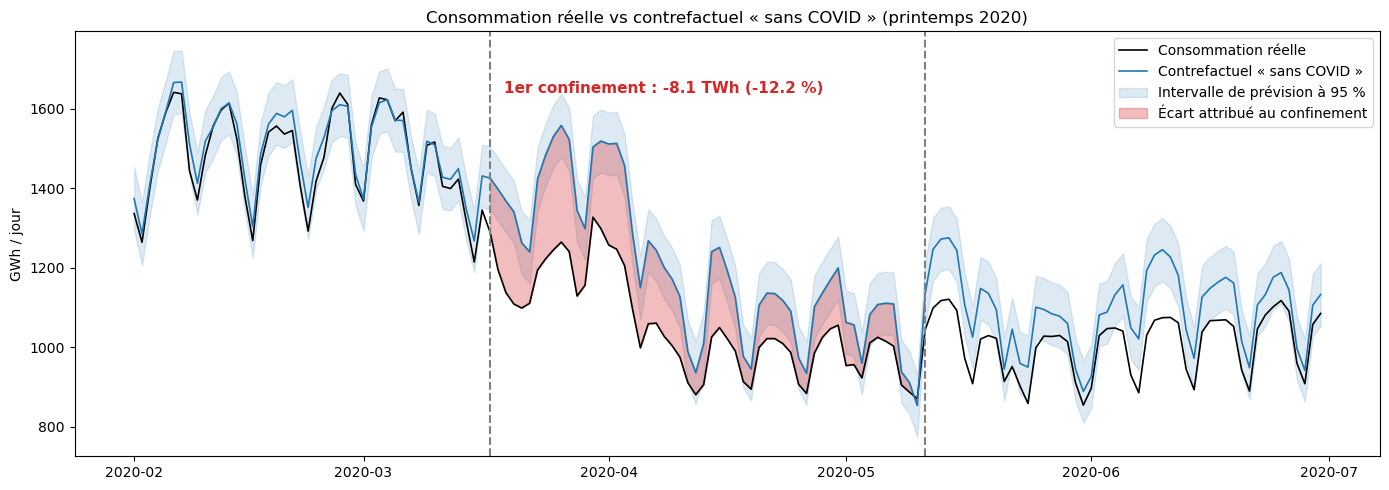

In [4]:
# CELLULE 9 : CONTREFACTUEL COVID

m_covid = ajuster("2016-01-01", "2020-02-29")             # apprentissage avant la crise

# --- Écarts sur deux fenêtres ---
periodes = {
    "Confinement complet (17/03 → 10/05/2020)": ("2020-03-17", "2020-05-10"),
    "Fenêtre INSEE (23/03 → 26/04/2020)": ("2020-03-23", "2020-04-26"),   # pour comparer à l'INSEE
}
res_covid = pd.DataFrame({nom: ecart(m_covid, *dates) for nom, dates in periodes.items()}).T.round(2)
res_covid.to_csv("figures/resultats_covid.csv")
print(res_covid.to_string())

# --- Graphique réel vs contrefactuel ---
fen = slice("2020-02-01", "2020-06-30")
pred = m_covid.get_prediction(X.loc[fen]).summary_frame(alpha=0.05)   # prévision + intervalle à 95 %
conf = slice("2020-03-17", "2020-05-10")

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(y.loc[fen].index, y.loc[fen], color="black", lw=1.2, label="Consommation réelle")
ax.plot(pred.index, pred["mean"], color="tab:blue", lw=1.2, label="Contrefactuel « sans COVID »")
ax.fill_between(pred.index, pred["obs_ci_lower"], pred["obs_ci_upper"], color="tab:blue", alpha=0.15, label="Intervalle de prévision à 95 %")
ax.fill_between(y.loc[conf].index, y.loc[conf], pred.loc[conf, "mean"], color="tab:red", alpha=0.3, label="Écart attribué au confinement")
ax.axvline(pd.Timestamp("2020-03-17"), color="grey", ls="--")
ax.axvline(pd.Timestamp("2020-05-11"), color="grey", ls="--")
e = res_covid.iloc[0]
ax.text(pd.Timestamp("2020-04-08"), 1640, f"1er confinement : {e['ecart_twh']:.1f} TWh ({e['ecart_pct']:.1f} %)",
        ha="center", fontsize=11, color="tab:red", fontweight="bold")
ax.set_title("Consommation réelle vs contrefactuel « sans COVID » (printemps 2020)")
ax.set_ylabel("GWh / jour")
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/contrefactuel_covid.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation
Le premier confinement a réduit la consommation d'électricité d'environ **8,1 TWh**, soit
**−12,2 %** par rapport à ce qu'elle aurait été sans COVID à météo et calendrier identiques.
Sur la fenêtre étudiée par l'INSEE (23 mars-26 avril), on obtient **−13,5 %**, très proche
des **−14 %** publiés par l'INSEE avec une méthode comparable : notre modèle retrouve le chiffre officiel.
L'effet est maximal fin mars (arrêt brutal de l'industrie et des services) puis s'atténue
progressivement : la consommation résidentielle augmente (télétravail) et l'activité reprend.
Corrigé du biais du modèle (≈ −1 point), l'effet propre du confinement est d'environ −11 %.
Source : INSEE, Note de conjoncture du 7 mai 2020, éclairage « consommation d'électricité ».

## 4. Contrefactuel n°2 : crise énergétique et sobriété (hivers 2022-23 à 2024-25)
Modèle entraîné sur 2016-2019 uniquement (comportement « d'avant les crises », période COVID exclue),
puis utilisé pour prédire les hivers suivants.
On s'arrête à l'hiver 2024-25 pour ne pas toucher à la période de test du groupe (à partir du 07/08/2025).

               reel_twh  contrefactuel_twh  ecart_twh  ecart_pct
Hiver 2022-23    243.54             265.49     -21.96      -8.27
Hiver 2023-24    244.42             263.36     -18.95      -7.19
Hiver 2024-25    252.26             269.99     -17.74      -6.57


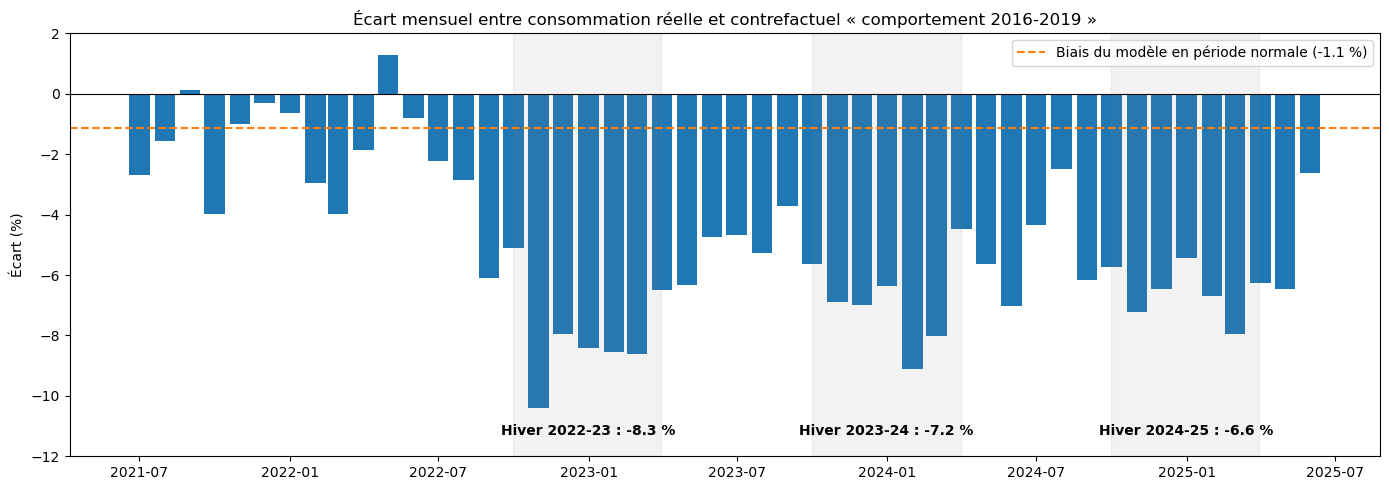

In [5]:
# CELLULE 12 : CONTREFACTUEL SOBRIÉTÉ

m_sobriete = ajuster("2016-01-01", "2019-12-31")          # comportement de référence 2016-2019

# --- Écart hiver par hiver (octobre → mars) ---
hivers = {
    "Hiver 2022-23": ("2022-10-01", "2023-03-31"),
    "Hiver 2023-24": ("2023-10-01", "2024-03-31"),
    "Hiver 2024-25": ("2024-10-01", "2025-03-31"),
}
res_sob = pd.DataFrame({nom: ecart(m_sobriete, *dates) for nom, dates in hivers.items()}).T.round(2)
res_sob.to_csv("figures/resultats_sobriete.csv")
print(res_sob.to_string())

# --- Écart mensuel en % de juillet 2021 à juin 2025 ---
fen = slice("2021-07-01", "2025-06-30")
prevu = m_sobriete.predict(X.loc[fen])
ecart_mensuel = (y.loc[fen].resample("MS").sum() / prevu.resample("MS").sum() - 1) * 100

fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(ecart_mensuel.index, ecart_mensuel, width=25, color="tab:blue")
ax.axhline(0, color="black", lw=0.8)
biais = validation["biais_%"].mean()                     # biais du modèle en période normale (cellule 6)
ax.axhline(biais, color="tab:orange", ls="--", label=f"Biais du modèle en période normale ({biais:.1f} %)")
for nom, (debut, fin) in hivers.items():
    ax.axvspan(pd.Timestamp(debut), pd.Timestamp(fin), color="grey", alpha=0.1)
    ax.text(pd.Timestamp(debut) + pd.Timedelta(days=91), -11.3, f"{nom} : {res_sob.loc[nom, 'ecart_pct']:.1f} %",
            ha="center", fontsize=10, fontweight="bold")
ax.set_title("Écart mensuel entre consommation réelle et contrefactuel « comportement 2016-2019 »")
ax.set_ylabel("Écart (%)")
ax.set_ylim(-12, 2)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig("figures/contrefactuel_sobriete.png", dpi=150, bbox_inches="tight")
plt.show()

### Interprétation
À météo et calendrier égaux, la consommation de l'hiver 2022-23 est inférieure de **8,3 %**
(≈ 22 TWh) à celle qu'aurait produite le comportement de 2016-2019. RTE estime la baisse
à « environ 9 % » par rapport à 2014-2019, corrigée de la météo : notre estimation est cohérente.
Le décrochage commence en septembre-octobre 2022 (flambée des prix, appels à la sobriété,
lancement d'Ecowatt) et culmine en novembre 2022 (−10,4 %).
Fait marquant : **la baisse ne disparaît pas** (−7,2 % en 2023-24, −6,6 % en 2024-25).
Une partie de la sobriété est devenue structurelle (habitudes, équipements, industrie
électro-intensive qui n'a pas retrouvé son niveau), même après la baisse des prix.
Avant la crise (2021-22), les écarts restent entre 0 et −4 % : séquelles du COVID et biais
du modèle (≈ −1 %), ce qui borne l'incertitude de la mesure.
Source : RTE, cité par l'AFP / Connaissance des Énergies, mars 2023.

## 5. Synthèse

| Choc | Période | Écart estimé | Référence officielle |
|---|---|---|---|
| 1er confinement | 17/03 → 10/05/2020 | −8,1 TWh (−12,2 %) | — |
| 1er confinement | 23/03 → 26/04/2020 | −5,8 TWh (−13,5 %) | INSEE : −14 % |
| Sobriété | Hiver 2022-23 | −22,0 TWh (−8,3 %) | RTE : ≈ −9 % (vs 2014-2019) |
| Sobriété | Hiver 2023-24 | −19,0 TWh (−7,2 %) | — |
| Sobriété | Hiver 2024-25 | −17,7 TWh (−6,6 %) | — |

**Limites**
- Biais du modèle en période normale ≈ −1 % : les effets sont possiblement surestimés d'environ 1 point.
- Résidus autocorrélés (MCO) : les intervalles de prévision à 95 % sont probablement trop étroits.
- Température nationale non pondérée par la population (Corse = Île-de-France).
- Le contrefactuel attribue au choc tout ce que le modèle n'explique pas (prix de l'électricité,
  activité économique, évolution du parc : pompes à chaleur, véhicules électriques).
- RTE compare à 2014-2019, nous à 2016-2019 : périodes de référence proches mais pas identiques.